In [8]:
from PIL import Image
from starvector.model.starvector_arch import StarVectorForCausalLM
from starvector.data.util import process_and_rasterize_svg
import torch

model_name = "starvector/starvector-1b-im2svg"
#model_name = "starvector/starvector-8b-im2svg"

starvector = StarVectorForCausalLM.from_pretrained(model_name, torch_dtype=torch.float16)

starvector.cuda()
starvector.eval()


trainable params: 0 || all params: 1434095106 || trainable%: 0.0


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

StarVectorForCausalLM(
  (model): StarVectorStarCoder(
    (svg_transformer): StarCoderModel(
      (transformer): GPTBigCodeForCausalLM(
        (transformer): GPTBigCodeModel(
          (wte): Embedding(49156, 2048)
          (wpe): Embedding(8192, 2048)
          (drop): Dropout(p=0.1, inplace=False)
          (h): ModuleList(
            (0-23): 24 x GPTBigCodeBlock(
              (ln_1): LayerNorm((2048,), eps=1e-05, elementwise_affine=True)
              (attn): GPTBigCodeFlashAttention2(
                (c_attn): Linear(in_features=2048, out_features=2304, bias=True)
                (c_proj): Linear(in_features=2048, out_features=2048, bias=True)
                (attn_dropout): Dropout(p=0.1, inplace=False)
                (resid_dropout): Dropout(p=0.1, inplace=False)
              )
              (ln_2): LayerNorm((2048,), eps=1e-05, elementwise_affine=True)
              (mlp): GPTBigCodeMLP(
                (c_fc): Linear(in_features=2048, out_features=8192, bias=True)
     

In [9]:
image_pil = Image.open('../assets/examples/sample-18.png')

image = starvector.process_images([image_pil])[0].cuda()
batch = {"image": image}

raw_svg = starvector.generate_im2svg(batch, max_length=5000)[0]
svg, raster_image = process_and_rasterize_svg(raw_svg)

Asking to truncate to max_length but no maximum length is provided and the model has no predefined maximum length. Default to no truncation.


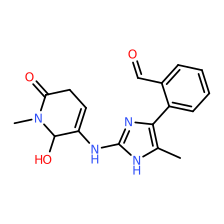

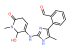

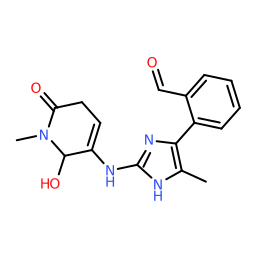

In [10]:
from IPython.display import SVG, display

display(image_pil)
display(SVG(svg))
display(raster_image)

In [6]:
del starvector
torch.cuda.empty_cache()